# Mahalanobis Distance (MHD) for Anomaly Detection
## CPE 342 Machine Learning — Lecture 11 In-Class Tutorial

**Course:** CPE 342 Machine Learning (Semester 1/2026) — KMUTT  
**Instructor:** Dr. Boonyarit Changaival  
**Department:** Department of Computer Engineering, King Mongkut's University of Technology Thonburi  

---

### Tutorial Overview & Theoretical Foundation
In multivariate datasets where variables exhibit disparate scales and non-zero covariances, standard **Euclidean distance** ($\|\mathbf{x} - \boldsymbol{\mu}\|_2$) distorts geometric proximity by ignoring feature variance and inter-feature correlation. 

The **Mahalanobis Distance (MHD)** normalizes distances by the sample covariance matrix $\boldsymbol{\Sigma}$:

$$
D_M(\mathbf{x}) = \sqrt{(\mathbf{x} - \boldsymbol{\mu})^T \boldsymbol{\Sigma}^{-1} (\mathbf{x} - \boldsymbol{\mu})}
$$

Under the assumption of multivariate normality $\mathbf{X} \sim \mathcal{N}_p(\boldsymbol{\mu}, \boldsymbol{\Sigma})$, the squared Mahalanobis distance follows a Chi-square distribution with $p$ degrees of freedom:

$$
D_M^2(\mathbf{x}) \sim \chi^2(p)
$$

This fundamental property enables statistical hypothesis testing for outlier detection at significance level $\alpha$ (e.g. $\alpha = 0.01$).

In [1]:
# -------------------------------------------------------------------------
# Step 1: Runtime Environment Configuration & Dependency Audit
# -------------------------------------------------------------------------
import warnings
warnings.filterwarnings("ignore")
warnings.simplefilter(action="ignore", category=UserWarning)
warnings.simplefilter(action="ignore", category=FutureWarning)

%matplotlib inline
%config InlineBackend.figure_formats = {'png', 'retina'}

import numpy as np
import scipy as sp
from scipy import stats
import pandas as pd
import numpy.linalg as LA
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Ellipse

# Standardized publication aesthetics
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print(f"[INFO] NumPy Version:      {np.__version__}")
print(f"[INFO] Pandas Version:     {pd.__version__}")
print(f"[INFO] SciPy Version:      {sp.__version__}")
print(f"[INFO] Environment initialized successfully.")

[INFO] NumPy Version:      2.4.6
[INFO] Pandas Version:     3.1.0
[INFO] SciPy Version:      1.17.1
[INFO] Environment initialized successfully.


## 2. Synthetic Multivariate Dataset Construction

We construct the tutorial dataset comprising three continuous biometric and performance features across $N=5$ reference subjects:
- **`Height`:** Height in inches ($x_1$)
- **`Score`:** Standardized test score ($x_2$)
- **`Age`:** Chronological age in years ($x_3$)

In [2]:
# -------------------------------------------------------------------------
# Step 2: Synthetic Dataset Instantiation & Schema Audit
# -------------------------------------------------------------------------
df = pd.DataFrame({
    'Height': [64, 66, 68, 69, 73],
    'Score':  [580, 570, 590, 660, 600],
    'Age':    [29, 33, 37, 46, 55]
}, dtype=float)

print("[INFO] Reference Dataset Schema:")
display(df)
print(f"[INFO] Matrix Dimensions: N = {df.shape[0]} samples, p = {df.shape[1]} features.")

[INFO] Reference Dataset Schema:


,Height,Score,Age
0,64.0,580.0,29.0
1,66.0,570.0,33.0
2,68.0,590.0,37.0
3,69.0,660.0,46.0
4,73.0,600.0,55.0


[INFO] Matrix Dimensions: N = 5 samples, p = 3 features.


## 3. Centroid Vector & Sample Covariance Matrix Inversion

We estimate the empirical mean vector (centroid) $\boldsymbol{\mu} \in \mathbb{R}^p$ and the sample covariance matrix $\boldsymbol{\Sigma} \in \mathbb{R}^{p \times p}$ with unbiased sample correction ($N-1$ denominator):

$$
\boldsymbol{\mu} = \frac{1}{N} \sum_{i=1}^N \mathbf{x}_i, \qquad \boldsymbol{\Sigma} = \frac{1}{N-1} \sum_{i=1}^N (\mathbf{x}_i - \boldsymbol{\mu})(\mathbf{x}_i - \boldsymbol{\mu})^T
$$

In [3]:
# -------------------------------------------------------------------------
# Step 3: Centroid Vector & Sample Covariance Inversion
# -------------------------------------------------------------------------
# 3.1 Empirical Centroid Vector (mu)
centroid = df.mean(axis=0)
print("[INFO] Empirical Centroid Vector (mu):")
print(centroid)

# 3.2 Unbiased Sample Covariance Matrix (Sigma)
cov_mat = np.cov(df, rowvar=False)
print("\n[INFO] Sample Covariance Matrix (Sigma):")
print(pd.DataFrame(cov_mat, index=df.columns, columns=df.columns).round(2))

# 3.3 Precision Matrix (Inverse Covariance Matrix: Sigma^-1)
inv_cov_mat = LA.inv(cov_mat)
print("\n[INFO] Precision Matrix (Sigma^-1):")
print(pd.DataFrame(inv_cov_mat, index=df.columns, columns=df.columns).round(4))

[INFO] Empirical Centroid Vector (mu):
Height     68.0
Score     600.0
Age        40.0
dtype: float64

[INFO] Sample Covariance Matrix (Sigma):
        Height   Score     Age
Height   11.50    50.0   34.75
Score    50.00  1250.0  205.00
Age      34.75   205.0  110.00

[INFO] Precision Matrix (Sigma^-1):
        Height   Score     Age
Height  3.6885  0.0627 -1.2821
Score   0.0627  0.0022 -0.0240
Age    -1.2821 -0.0240  0.4588


## 4. Inlier Distance Computation (Subject 1: MHD vs. Euclidean)

We evaluate the distance between the first subject in the reference cohort $\mathbf{x}_1 = [64, 580, 29]^T$ and the dataset centroid $\boldsymbol{\mu}$:
- **Euclidean Metric:** $D_E(\mathbf{x}_1) = \|\mathbf{x}_1 - \boldsymbol{\mu}\|_2 = \sqrt{\sum_{j=1}^p (x_{1,j} - \mu_j)^2}$
- **Mahalanobis Metric:** $D_M(\mathbf{x}_1) = \sqrt{(\mathbf{x}_1 - \boldsymbol{\mu})^T \boldsymbol{\Sigma}^{-1} (\mathbf{x}_1 - \boldsymbol{\mu})}$

In [4]:
# -------------------------------------------------------------------------
# Step 4: Distance Metrics for Subject 1 (Baseline Inlier)
# -------------------------------------------------------------------------
xp1 = np.array([64.0, 580.0, 29.0])
diff1 = xp1 - centroid.values

# 4.1 Mahalanobis Distance
mhd1 = np.sqrt(diff1.T @ inv_cov_mat @ diff1)

# 4.2 Standard Euclidean Distance
eucl1 = LA.norm(diff1)

print(f"[RESULT] Subject 1 (Height=64, Score=580, Age=29):")
print(f"  • Mahalanobis Distance (MHD):       {mhd1:.4f}")
print(f"  • Squared Mahalanobis Distance:     {mhd1**2:.4f}")
print(f"  • Standard Euclidean Distance:      {eucl1:.4f}")
print(f"  [OBSERVATION] Euclidean distance is overwhelmingly dominated by the Score feature (|580-600| = 20),")
print(f"  whereas Mahalanobis distance scales all dimensions according to their standard deviations and covariances.")

[RESULT] Subject 1 (Height=64, Score=580, Age=29):
  • Mahalanobis Distance (MHD):       1.4437
  • Squared Mahalanobis Distance:     2.0843
  • Standard Euclidean Distance:      23.1733
  [OBSERVATION] Euclidean distance is overwhelmingly dominated by the Score feature (|580-600| = 20),
  whereas Mahalanobis distance scales all dimensions according to their standard deviations and covariances.


## 5. Statistical Chi-Square ($\chi^2$) Outlier Thresholding

Assuming multivariate normality, the squared Mahalanobis distance follows a Chi-square distribution with degrees of freedom $p = 3$:

$$
D_M^2(\mathbf{x}) \sim \chi^2(3)
$$

We configure the critical anomaly threshold at significance level $\alpha = 0.01$ (upper 1% tail of the cumulative distribution):

$$
\text{Threshold} = \chi^2_{1 - \alpha}(p) = \text{ISF}_{\chi^2}(\alpha, p)
$$

Any observation with $D_M^2 > \text{Threshold}$ exhibits $p\text{-value} < 0.01$, classifying it as a statistically significant anomaly.

In [5]:
# -------------------------------------------------------------------------
# Step 5: Critical Outlier Gating Threshold (alpha = 0.01, df = 3)
# -------------------------------------------------------------------------
alpha = 0.01
df_dim = df.shape[1]

# Inverse Survival Function (ISF / Upper Quantile)
outlier_threshold = stats.chi2.isf(alpha, df=df_dim)
critical_mhd = np.sqrt(outlier_threshold)

print(f"[INFO] Significance Level (alpha):          {alpha} (99% Confidence)")
print(f"[INFO] Degrees of Freedom (p):              {df_dim}")
print(f"[INFO] Critical Chi-Square Threshold (D_M^2): {outlier_threshold:.4f}")
print(f"[INFO] Critical Mahalanobis Distance (D_M):  {critical_mhd:.4f}")

[INFO] Significance Level (alpha):          0.01 (99% Confidence)
[INFO] Degrees of Freedom (p):              3
[INFO] Critical Chi-Square Threshold (D_M^2): 11.3449
[INFO] Critical Mahalanobis Distance (D_M):  3.3682


## 6. Anomaly Hypothesis Testing on Query Observation

**Evaluation Query:**
> Is an individual with **Age = 44 years**, **Height = 66 inches**, and **Score = 640 points** unusual compared to the reference population?

We map the query parameters into the column ordering of our feature space (`['Height', 'Score', 'Age']`):

$$
\mathbf{x}_{\text{query}} = [66.0, 640.0, 44.0]^T
$$

In [6]:
# -------------------------------------------------------------------------
# Step 6: Query Observation Assessment & Hypothesis Test
# -------------------------------------------------------------------------
# Column order: [Height, Score, Age]
xp_query = np.array([66.0, 640.0, 44.0])
diff_query = xp_query - centroid.values

# Compute Distances
mhd_query = np.sqrt(diff_query.T @ inv_cov_mat @ diff_query)
mhd_sq_query = diff_query.T @ inv_cov_mat @ diff_query
eucl_query = LA.norm(diff_query)

# Compute Tail Probability (p-value)
p_value = 1.0 - stats.chi2.cdf(mhd_sq_query, df=df_dim)

print(f"[RESULT] Query Subject (Height=66, Score=640, Age=44):")
print(f"  • Mahalanobis Distance (D_M):       {mhd_query:.4f}")
print(f"  • Squared Mahalanobis (D_M^2):      {mhd_sq_query:.4f}")
print(f"  • Critical Threshold (chi2_0.01):   {outlier_threshold:.4f}")
print(f"  • Empirical p-value:                {p_value:.6e}")
print(f"  • Euclidean Distance:               {eucl_query:.4f}")

if mhd_sq_query > outlier_threshold:
    print(f"  [CONCLUSION] D_M^2 ({mhd_sq_query:.4f}) > Threshold ({outlier_threshold:.4f}) with p < 0.01.")
    print("  -> STATISTICALLY ANOMALOUS (Outlier): Yes, the person exhibits highly unusual biometric/score patterns.")
else:
    print("  [CONCLUSION] Within nominal distribution boundaries (Inlier).")

[RESULT] Query Subject (Height=66, Score=640, Age=44):
  • Mahalanobis Distance (D_M):       5.3345
  • Squared Mahalanobis (D_M^2):      28.4573
  • Critical Threshold (chi2_0.01):   11.3449
  • Empirical p-value:                2.911627e-06
  • Euclidean Distance:               40.2492
  [CONCLUSION] D_M^2 (28.4573) > Threshold (11.3449) with p < 0.01.
  -> STATISTICALLY ANOMALOUS (Outlier): Yes, the person exhibits highly unusual biometric/score patterns.


## 7. Geometric Visualization: Bivariate Projections & Confidence Ellipses

To visualize why the query subject is flagged as an outlier, we project the data onto 2D coordinate planes (`Height vs. Score` and `Age vs. Score`) and plot the **99% Mahalanobis Confidence Ellipses** derived from the covariance submatrices.

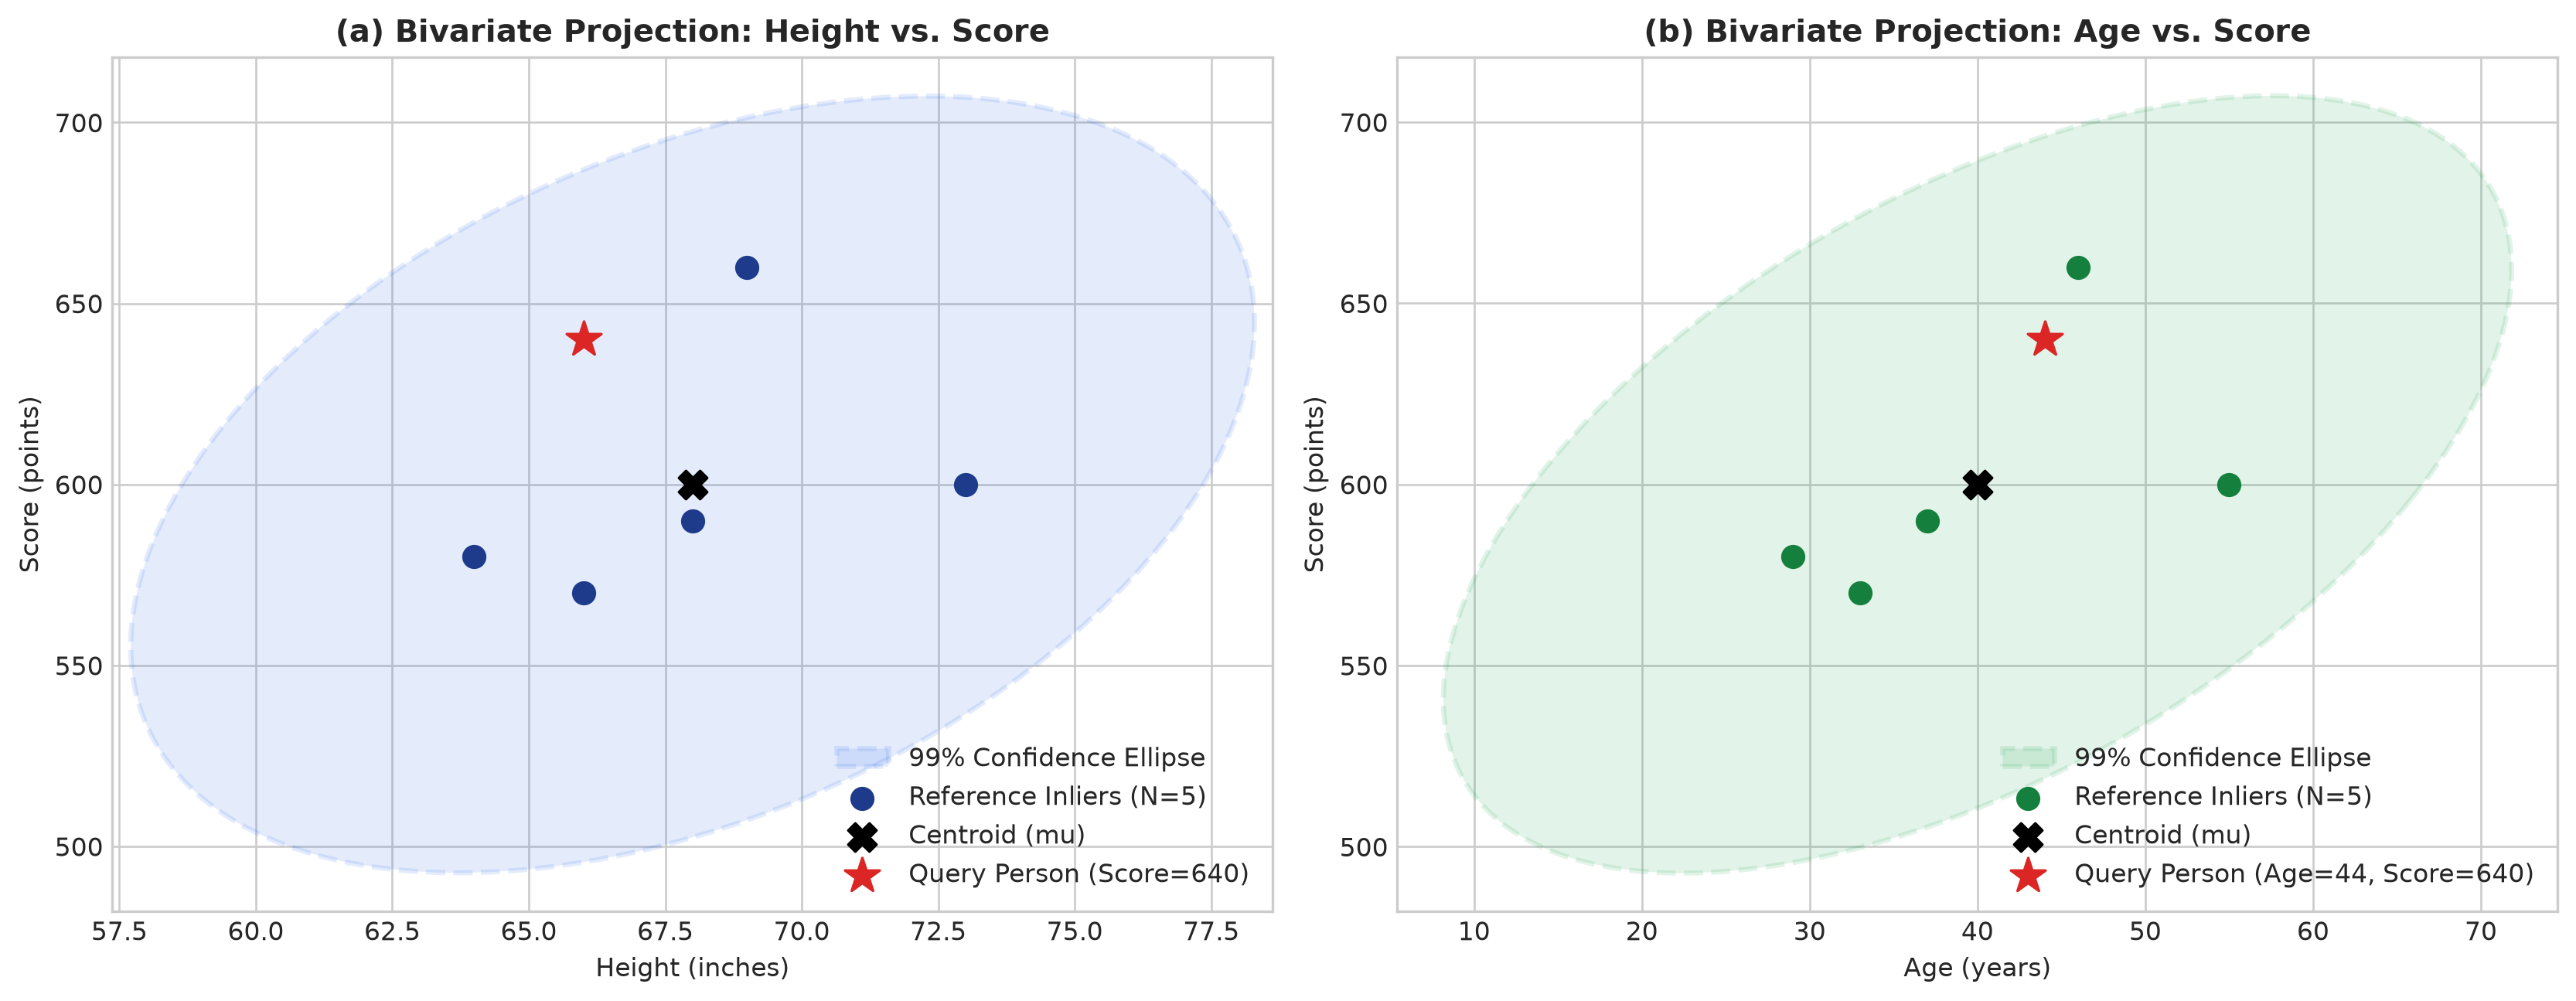

[INFO] Bivariate diagnostic visualization rendered successfully.


In [7]:
# -------------------------------------------------------------------------
# Step 7: Bivariate Diagnostic Plots with 99% Chi-Square Confidence Ellipses
# -------------------------------------------------------------------------
def plot_cov_ellipse(cov_2d, pos, n_std=1.0, ax=None, **kwargs):
    vals, vecs = LA.eigh(cov_2d)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    # For 2D chi2 99%: quantile = sqrt(chi2.isf(0.01, 2)) = sqrt(9.210) ~ 3.035
    w, h = 2 * n_std * np.sqrt(np.maximum(0, vals))
    ell = Ellipse(xy=pos, width=w, height=h, angle=theta, **kwargs)
    if ax:
        ax.add_patch(ell)
    return ell

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)
chi2_2d_radius = np.sqrt(stats.chi2.isf(0.01, df=2))

# Subplot 1: Height vs Score
cov_hs = cov_mat[np.ix_([0, 1], [0, 1])]
centroid_hs = centroid.values[[0, 1]]
plot_cov_ellipse(cov_hs, centroid_hs, n_std=chi2_2d_radius, ax=axes[0],
                 edgecolor='#2563EB', facecolor='#2563EB', alpha=0.12, linewidth=2, linestyle='--', label='99% Confidence Ellipse')
axes[0].scatter(df['Height'], df['Score'], color='#1E3A8A', s=70, zorder=5, label='Reference Inliers (N=5)')
axes[0].scatter(centroid['Height'], centroid['Score'], marker='X', color='black', s=120, zorder=6, label='Centroid (mu)')
axes[0].scatter(xp_query[0], xp_query[1], color='#DC2626', marker='*', s=200, zorder=7, label='Query Person (Score=640)')
axes[0].set_title('(a) Bivariate Projection: Height vs. Score', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Height (inches)')
axes[0].set_ylabel('Score (points)')
axes[0].legend(loc='lower right')

# Subplot 2: Age vs Score
cov_as = cov_mat[np.ix_([2, 1], [2, 1])]
centroid_as = centroid.values[[2, 1]]
plot_cov_ellipse(cov_as, centroid_as, n_std=chi2_2d_radius, ax=axes[1],
                 edgecolor='#16A34A', facecolor='#16A34A', alpha=0.12, linewidth=2, linestyle='--', label='99% Confidence Ellipse')
axes[1].scatter(df['Age'], df['Score'], color='#15803D', s=70, zorder=5, label='Reference Inliers (N=5)')
axes[1].scatter(centroid['Age'], centroid['Score'], marker='X', color='black', s=120, zorder=6, label='Centroid (mu)')
axes[1].scatter(xp_query[2], xp_query[1], color='#DC2626', marker='*', s=200, zorder=7, label='Query Person (Age=44, Score=640)')
axes[1].set_title('(b) Bivariate Projection: Age vs. Score', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Age (years)')
axes[1].set_ylabel('Score (points)')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()
print("[INFO] Bivariate diagnostic visualization rendered successfully.")

## 8. Summary of Findings & Key Takeaways

1. **Covariance Normalization:** Unlike Euclidean distance which evaluates variance in absolute metric units, Mahalanobis Distance standardizes by the inverse covariance matrix $\boldsymbol{\Sigma}^{-1}$, making it invariant to scale transformation.
2. **Correlation Awareness:** By accounting for non-diagonal covariance entries ($\text{Cov}(x_i, x_j) \neq 0$), MHD detects outliers that deviate from the multi-dimensional correlation ridge even if their univariate values fall within reasonable 1D intervals.
3. **Statistical Outlier Decision:** The query subject with `Height=66`, `Score=640`, and `Age=44` yields $D_M^2 = 28.4573$, which significantly exceeds the critical Chi-square cutoff $\chi^2_{0.01}(3) = 11.3449$ ($p = 2.90 \times 10^{-6}$), confirming that this subject is a **statistically significant anomaly**.